# Exercises week 42 — solutions

**October 12–16, 2026**

This notebook contains the full solution of the week-42 exercise set
(`exercisesweek42.ipynb`), with explanations, followed by a discussion of
the insights the exercises are meant to give you. Every code cell has been
executed, so you can compare your own numbers with ours: the set-up cell
fixes the seed and the solutions draw the random numbers in the same order as
the exercise notebook, so if you used `np.random.rand` for the weights and
biases of exercise 2 as we do, your numbers in exercises 2–5 are ours.

The theme of the week is the **backpropagation algorithm**, Section
[8.8](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#backpropagation) of the lecture notes: the gradient of the cost
function with respect to every weight and bias of a dense network, computed
by the chain rule from the output layer backwards, and then used to train the
network. At every step we check the hand-written gradient against `jax.grad`.

Exercises 2–5 use the **single-vector convention** (one input vector at a
time, weights of shape (outputs, inputs), $z = Wx + b$); exercise 6 switches
to the **batched convention** of the lecture notes (samples in rows, weights
of shape (inputs, outputs), $Z = XW + b$, Eq. (8.21)), which exercises 7 and
8 and Project 2 use.

The set-up cell is the one from the exercise notebook, unchanged.


In [1]:
import numpy as np
import jax
jax.config.update("jax_enable_x64", True)   # 64-bit floats, so that results agree with numpy to ~1e-15
import jax.numpy as jnp                    # numpy-compatible functions that JAX can differentiate
from sklearn import datasets
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

np.random.seed(2026)   # so that your numbers can be compared with those of other students


# Defining some activation functions
def ReLU(z):
    return jnp.where(z > 0, z, 0.0)


# Derivative of the ReLU function
def ReLU_der(z):
    return jnp.where(z > 0, 1.0, 0.0)


def sigmoid(z):
    return 1 / (1 + jnp.exp(-z))


def mse(predict, target):
    return jnp.mean((predict - target) ** 2)

# Exercise 1 — understand the feed-forward pass

The exercise asks you to finish last week's set and to be sure about the
shapes of `W`, `b`, `z` and `a` in the two conventions, because *every
gradient below has the shape of the parameter it belongs to*. The table is
worth having in front of you for the rest of the notebook. A layer with
$n_{\text{in}}$ inputs and $n_{\text{out}}$ outputs:

| | single vector (exercises 2–5) | batched, $n$ samples (exercise 6 onwards) |
|---|---|---|
| input $x$ / $X$ | $(n_{\text{in}},)$ | $(n, n_{\text{in}})$ |
| weights $W$ | $(n_{\text{out}}, n_{\text{in}})$ | $(n_{\text{in}}, n_{\text{out}})$ |
| bias $b$ | $(n_{\text{out}},)$ | $(n_{\text{out}},)$, broadcast to every row |
| $z$ | $Wx + b$, $(n_{\text{out}},)$ | $XW + b$, $(n, n_{\text{out}})$ |
| $a = f(z)$ | $(n_{\text{out}},)$ | $(n, n_{\text{out}})$ |
| $\partial C/\partial W$ | $(n_{\text{out}}, n_{\text{in}})$ | $(n_{\text{in}}, n_{\text{out}})$ |
| $\partial C/\partial b$ | $(n_{\text{out}},)$ | $(n_{\text{out}},)$ |

The two weight matrices are each other's transpose; the full solution of the
week-41 set is in `exercisesweek41_solutions.ipynb`.


# Exercise 2 — gradient of one layer with JAX

**a) Shapes of the gradients.** The cost $C$ is a single number. Its
gradient with respect to an array collects one partial derivative
$\partial C/\partial W_{ij}$ per entry of the array, so the gradient has the
shape of the array itself: $\partial C/\partial W$ has shape (10, 4) and
$\partial C/\partial b$ has shape (10,). This is the one fact about shapes
that never changes, whatever the convention: a gradient is a number per
parameter, arranged like the parameters.

**b) `feed_forward_one_layer`.** With two inputs and three outputs the
weights have shape (3, 2) and the bias shape (3,). We draw them with
`np.random.rand`, as the input and the target are drawn, so the order of
random draws of the exercise notebook is kept.


In [2]:
def feed_forward_one_layer(W, b, x):
    z = W @ x + b
    a = sigmoid(z)
    return a


def cost_one_layer(W, b, x, target):
    predict = feed_forward_one_layer(W, b, x)
    return mse(predict, target)


x = np.random.rand(2)
target = np.random.rand(3)

W = np.random.rand(3, 2)
b = np.random.rand(3)

print("x", x.shape, " target", target.shape, " W", W.shape, " b", b.shape)
print("output a", feed_forward_one_layer(W, b, x).shape)

x (2,)  target (3,)  W (3, 2)  b (3,)
output a (3,)


**c) The gradient with JAX.** `jax.grad(cost_one_layer, argnums=(0, 1))`
returns a new function with the same arguments as `cost_one_layer` that
returns the gradients with respect to the first two arguments, `W` and `b`,
as a tuple. The shapes are those predicted in a).


In [3]:
jax_one_layer = jax.grad(cost_one_layer, argnums=(0, 1))
W_g, b_g = jax_one_layer(W, b, x, target)
print(W_g, b_g)
print("shapes:", W_g.shape, b_g.shape)

[[-0.01004511 -0.01891421]
 [ 0.01879958  0.03539823]
 [ 0.00751831  0.01415642]] [-0.04579581  0.08570757  0.03427607]
shapes: (3, 2) (3,)


# Exercise 3 — one layer, backpropagation by hand

The cost is a function of the output activation, which is a function of
$z$, which is a function of $W$ and $b$. The chain rule splits the gradient
into factors we can write down one at a time:

$$
\frac{dC}{dW} = \frac{dC}{da}\frac{da}{dz}\frac{dz}{dW}, \qquad
\frac{dC}{db} = \frac{dC}{da}\frac{da}{dz}\frac{dz}{db}.
$$

**a) What is shared.** The first two factors, $\frac{dC}{da}\frac{da}{dz}
= \frac{dC}{dz}$, are the same in both expressions. This product is the
*error* of the layer, $\delta = \partial C/\partial z$ (Eq. (8.60)), and it
is computed once and used for both gradients. The two expressions differ
only in the last factor, which is trivial: $\partial z/\partial b$ is one
and $\partial z/\partial W$ is the layer input.

**b) Derivative of the cost with respect to the activation.** The cost is a
*mean* over the $n$ output components,
$C = \frac{1}{n}\sum_{i=1}^{n}(a_i - y_i)^2$, so

$$
\frac{\partial C}{\partial a_i} = \frac{2}{n}\,(a_i - y_i),
$$

a vector of the same shape as `predict`. The factor $2/n$ is easy to drop;
`jax.grad(mse)` shows that it belongs there. Forgetting it gives a gradient
that is wrong by a constant factor — the direction is right, the length is
not, and the learning rate silently absorbs the mistake until you compare
with somebody else's numbers.


In [4]:
z = W @ x + b
a = sigmoid(z)

predict = a


def mse_der(predict, target):
    return 2 * (predict - target) / len(predict)


print(mse_der(predict, target))

cost_jax = jax.grad(mse, argnums=0)
print(cost_jax(predict, target))
print(np.allclose(mse_der(predict, target), cost_jax(predict, target)))

[-0.20626037  0.39009356  0.19173103]
[-0.20626037  0.39009356  0.19173103]
True


**c) Derivative of the sigmoid.** With $\sigma(z) = 1/(1 + e^{-z})$,

$$
\sigma'(z) = \frac{e^{-z}}{(1 + e^{-z})^2} = \sigma(z)\bigl(1 - \sigma(z)\bigr),
$$

which is why the forward pass is worth saving: the derivative is a function
of the activation we already have. The sigmoid acts element by element, so
$da/dz$ is a diagonal matrix, and we never build it — we keep the diagonal
$\sigma'(z)$ as a vector and multiply element-wise. That is also what the JAX
line computes: the gradient of `sum(sigmoid(z))` with respect to `z` is
exactly the vector of element-wise derivatives.


In [5]:
def sigmoid_der(z):
    s = sigmoid(z)
    return s * (1 - s)


print(sigmoid_der(z))

sigmoid_jax = jax.grad(lambda z: jnp.sum(sigmoid(z)))   # element-wise derivative of an element-wise function
print(sigmoid_jax(z))
print(np.allclose(sigmoid_der(z), sigmoid_jax(z)))

[0.22202913 0.2197103  0.17877165]
[0.22202913 0.2197103  0.17877165]
True


**d) The error of the layer.** Element-wise product of the two vectors:
$\delta = \frac{dC}{dz} = \frac{dC}{da}\odot\sigma'(z)$, shape (3,).


In [6]:
dC_da = mse_der(predict, target)
dC_dz = dC_da * sigmoid_der(z)
print(dC_dz, dC_dz.shape)

[-0.04579581  0.08570757  0.03427607] (3,)


**e) Derivatives of $z$ with respect to the weights and the bias.** Written
out by components, $z_i = \sum_j W_{ij}x_j + b_i$, so

$$
\frac{\partial z_i}{\partial b_k} = \delta_{ik}, \qquad
\frac{\partial z_i}{\partial W_{jk}} = \delta_{ij}\,x_k .
$$

The bias part is the identity: $z_i$ depends on $b_i$ only, with coefficient
one. The weight part is the tricky one. Taken literally, $dz/dW$ is the
derivative of a vector (3 components) with respect to a matrix (3 × 2
entries), an object with three indices and shape (3, 3, 2); `jax.jacobian`
builds it and we can look at it below. But we never need it on its own. What
we need is the chain rule contracted with $\delta$,

$$
\frac{\partial C}{\partial W_{jk}} = \sum_i \frac{\partial C}{\partial z_i}\frac{\partial z_i}{\partial W_{jk}}
= \sum_i \delta_i\,\delta_{ij}\,x_k = \delta_j\,x_k ,
\qquad\text{i.e.}\qquad
\frac{\partial C}{\partial W} = \delta\, x^T ,
$$

the **outer product** of the error with the layer input, which has the shape
(3, 2) of $W$ as it must. In the same way
$\partial C/\partial b_k = \sum_i \delta_i\delta_{ik} = \delta_k$: *the error
is the bias gradient* (Eqs. (8.61)–(8.63)).


In [7]:
# the full three-index object, for the record ...
dz_dW = jax.jacobian(lambda W: W @ x + b)(W)
dz_db = jax.jacobian(lambda b: W @ x + b)(b)
print("dz/dW has shape", dz_dW.shape, "   dz/db has shape", dz_db.shape)
print("dz/db is the identity:", np.allclose(dz_db, np.eye(3)))
print("dz_i/dW_jk = delta_ij x_k:", np.allclose(dz_dW, np.einsum("ij,k->ijk", np.eye(3), x)))

# ... and its contraction with the error, which is all we ever use
print("contraction equals the outer product:",
      np.allclose(np.einsum("i,ijk->jk", dC_dz, dz_dW), np.outer(dC_dz, x)))

dz/dW has shape (3, 3, 2)    dz/db has shape (3, 3)
dz/db is the identity: True
dz_i/dW_jk = delta_ij x_k: True
contraction equals the outer product: True


**f) The gradients.** Four lines, in the order of the backward pass; the
forward pass that produced `z` and `a` was done in b).


In [8]:
dC_da = mse_der(predict, target)
dC_dz = dC_da * sigmoid_der(z)
dC_dW = np.outer(dC_dz, x)
dC_db = dC_dz

print(dC_dW, dC_db)

[[-0.01004511 -0.01891421]
 [ 0.01879958  0.03539823]
 [ 0.00751831  0.01415642]] [-0.04579581  0.08570757  0.03427607]


In [9]:
W_g, b_g = jax_one_layer(W, b, x, target)
print(W_g, b_g)
print(np.allclose(dC_dW, W_g), np.allclose(dC_db, b_g))
print("largest difference:", np.max(np.abs(dC_dW - W_g)), np.max(np.abs(dC_db - b_g)))

[[-0.01004511 -0.01891421]
 [ 0.01879958  0.03539823]
 [ 0.00751831  0.01415642]] [-0.04579581  0.08570757  0.03427607]
True True
largest difference: 3.469446951953614e-18 1.3877787807814457e-17


# Exercise 4 — two layers, backpropagation by hand

A 2 → 3 → 4 network with sigmoid activations in both layers, one input
vector. The cells below are those of the exercise notebook (same random
draws).


In [10]:
x = np.random.rand(2)
target = np.random.rand(4)

W1 = np.random.rand(3, 2)
b1 = np.random.rand(3)

W2 = np.random.rand(4, 3)
b2 = np.random.rand(4)

layers = [(W1, b1), (W2, b2)]

In [11]:
z1 = W1 @ x + b1
a1 = sigmoid(z1)
z2 = W2 @ a1 + b2
a2 = sigmoid(z2)

**a) The last layer.** Exactly exercise 3 with the layer input $a_1$ in
place of $x$: the error $\delta_2 = \frac{2}{n}(a_2 - y)\odot\sigma'(z_2)$,
the weight gradient $\delta_2 a_1^T$ of shape (4, 3), the bias gradient
$\delta_2$.


In [12]:
dC_da2 = mse_der(a2, target)
dC_dz2 = dC_da2 * sigmoid_der(z2)
dC_dW2 = np.outer(dC_dz2, a1)
dC_db2 = dC_dz2
print(dC_dW2.shape, dC_db2.shape)

(4, 3) (4,)


**b) Propagating the error backwards.** The first layer's activation
enters the cost only through $z_2 = W_2 a_1 + b_2$, so

$$
\frac{\partial z_{2,i}}{\partial a_{1,j}} = W_{2,ij}, \qquad\text{i.e.}\qquad
\frac{dz_2}{da_1} = W_2 ,
$$

the Jacobian of a linear map is its matrix. Contracted with the error of
layer 2,

$$
\frac{\partial C}{\partial a_{1,j}} = \sum_i \frac{\partial C}{\partial z_{2,i}}\frac{\partial z_{2,i}}{\partial a_{1,j}}
= \sum_i W_{2,ij}\,\delta_{2,i}
\qquad\Longrightarrow\qquad
\frac{dC}{da_1} = W_2^T\,\delta_2 .
$$

This is the step that gives the algorithm its name (Eq. (8.64)): the same
matrix $W_2$ that carried the activations *forward* carries the error
*backward*, transposed, from the four output units to the three hidden
units. Note the shapes: $W_2^T$ is (3, 4), $\delta_2$ is (4,), the result is
(3,) like $a_1$.


In [13]:
dz2_da1 = jax.jacobian(lambda a1: W2 @ a1 + b2)(a1)
print("dz2/da1 has shape", dz2_da1.shape, "and equals W2:", np.allclose(dz2_da1, W2))

dC_da1 = W2.T @ dC_dz2
print("dC/da1 =", dC_da1, dC_da1.shape)

dz2/da1 has shape (4, 3) and equals W2: True
dC/da1 = [0.03151144 0.03074375 0.01320285] (3,)


**c) The first layer.** With $dC/da_1$ in hand the first layer is again
exercise 3: multiply by $\sigma'(z_1)$ to get $\delta_1$, then the outer
product with the layer input, which for the first layer is the network input
$x$.


In [14]:
dC_da1 = W2.T @ dC_dz2
dC_dz1 = dC_da1 * sigmoid_der(z1)
dC_dW1 = np.outer(dC_dz1, x)
dC_db1 = dC_dz1

In [15]:
print(dC_dW1, dC_db1)
print(dC_dW2, dC_db2)

[[0.00037557 0.00346971]
 [0.00035952 0.00332141]
 [0.00013004 0.00120135]] [0.00779593 0.00746271 0.00269925]
[[ 0.01022962  0.01086494  0.01324558]
 [ 0.01903882  0.02022125  0.02465197]
 [ 0.00372743  0.00395892  0.00482637]
 [-0.00685045 -0.00727591 -0.00887015]] [ 0.01856586  0.03455379  0.00676495 -0.01243297]


**d) Comparison with JAX.** `jax.grad` accepts the list of `(W, b)` tuples
as the argument to differentiate and returns a gradient with the same
structure.


In [16]:
def feed_forward_two_layers(layers, x):
    W1, b1 = layers[0]
    z1 = W1 @ x + b1
    a1 = sigmoid(z1)

    W2, b2 = layers[1]
    z2 = W2 @ a1 + b2
    a2 = sigmoid(z2)

    return a2

In [17]:
def cost_two_layers(layers, x, target):
    predict = feed_forward_two_layers(layers, x)
    return mse(predict, target)


grad_two_layers = jax.grad(cost_two_layers, argnums=0)
grads_jax = grad_two_layers(layers, x, target)
print(grads_jax)

for (dW, db), (dW_j, db_j) in zip([(dC_dW1, dC_db1), (dC_dW2, dC_db2)], grads_jax):
    print(np.allclose(dW, dW_j), np.allclose(db, db_j))

[(Array([[0.00037557, 0.00346971],
       [0.00035952, 0.00332141],
       [0.00013004, 0.00120135]], dtype=float64), Array([0.00779593, 0.00746271, 0.00269925], dtype=float64)), (Array([[ 0.01022962,  0.01086494,  0.01324558],
       [ 0.01903882,  0.02022125,  0.02465197],
       [ 0.00372743,  0.00395892,  0.00482637],
       [-0.00685045, -0.00727591, -0.00887015]], dtype=float64), Array([ 0.01856586,  0.03455379,  0.00676495, -0.01243297], dtype=float64))]
True True
True True


Notice how much smaller the first-layer gradients are than those of the
second layer: $\delta_1$ is $\delta_2$ multiplied by weights of order one and
by $\sigma'(z_1) \le 1/4$, and its norm comes out at about a quarter of that
of $\delta_2$. Every sigmoid layer the error passes through shrinks it by a
factor four at best, and by much more when the units are saturated — this is the *vanishing gradient* problem, the reason
deep sigmoid networks were hard to train and the ReLU took over
(Section [8.6](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#activation-functions)).


In [18]:
print("|delta_2| = %.4f   |delta_1| = %.4f   ratio %.3f"
      % (np.linalg.norm(dC_dz2), np.linalg.norm(dC_dz1), np.linalg.norm(dC_dz1) / np.linalg.norm(dC_dz2)))
print("sigma'(z1) =", sigmoid_der(z1), "  (at most 1/4)")

|delta_2| = 0.0417   |delta_1| = 0.0111   ratio 0.267
sigma'(z1) = [0.24739994 0.24273914 0.20444445]   (at most 1/4)


**e) An even earlier layer.** Nothing new is needed. If there were a layer
0 before layer 1, its error would be

$$
\delta_0 = \bigl(W_1^T \delta_1\bigr)\odot f'(z_0),
\qquad
\frac{\partial C}{\partial W_0} = \delta_0\, a_{-1}^T, \qquad
\frac{\partial C}{\partial b_0} = \delta_0 ,
$$

with $a_{-1}$ the input of that layer. The expressions are the same for
every layer; only the indices shift by one. The recursion
$\delta^{l} = (W^{l+1})^T\delta^{l+1}\odot f'(z^l)$ is what a loop over the
layers from the last to the first implements, and that is exercise 5.


# Exercise 5 — any number of layers

The general code from last week, one input vector at a time, and the
`feed_forward_saver` that keeps the layer inputs and the `z`s, because the
backward pass needs $f'(z^l)$ and $a^{l-1}$ for every layer.


In [19]:
def create_layers(network_input_size, layer_output_sizes):
    layers = []

    i_size = network_input_size
    for layer_output_size in layer_output_sizes:
        W = np.random.randn(layer_output_size, i_size)
        b = np.random.randn(layer_output_size)
        layers.append((W, b))

        i_size = layer_output_size
    return layers


def feed_forward(input, layers, activation_funcs):
    a = input
    for (W, b), activation_func in zip(layers, activation_funcs):
        z = W @ a + b
        a = activation_func(z)
    return a


def cost(layers, input, activation_funcs, target):
    predict = feed_forward(input, layers, activation_funcs)
    return mse(predict, target)

In [20]:
def feed_forward_saver(input, layers, activation_funcs):
    layer_inputs = []
    zs = []
    a = input
    for (W, b), activation_func in zip(layers, activation_funcs):
        layer_inputs.append(a)
        z = W @ a + b
        a = activation_func(z)

        zs.append(z)

    return layer_inputs, zs, a

**a) `backpropagation`.** The four equations of Section
[8.8.4](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#the-four-equations-of-backpropagation) in a loop that runs
from the last layer to the first:

1. output layer: $\delta^L = \frac{\partial C}{\partial a^L}\odot f'(z^L)$;
2. every other layer: $\delta^l = \bigl((W^{l+1})^T\delta^{l+1}\bigr)\odot f'(z^l)$;
3. $\partial C/\partial b^l = \delta^l$;
4. $\partial C/\partial W^l = \delta^l\,(a^{l-1})^T$.

The variable `dC_dz` carries $\delta^{l+1}$ from one iteration to the next,
which is why the loop must run backwards: at layer $l$ we need the error of
layer $l+1$, and only the output layer's error can be computed directly from
the cost.


In [21]:
def backpropagation(
    input, layers, activation_funcs, target, activation_ders, cost_der=mse_der
):
    layer_inputs, zs, predict = feed_forward_saver(input, layers, activation_funcs)

    layer_grads = [() for layer in layers]

    # We loop over the layers, from the last to the first
    for i in reversed(range(len(layers))):
        layer_input, z, activation_der = layer_inputs[i], zs[i], activation_ders[i]

        if i == len(layers) - 1:
            # For last layer we use cost derivative as dC_da(L) can be computed directly
            dC_da = cost_der(predict, target)
        else:
            # For other layers we build on previous z derivative, as dC_da(i) = dC_dz(i+1) * dz(i+1)_da(i)
            (W, b) = layers[i + 1]
            dC_da = W.T @ dC_dz

        dC_dz = dC_da * activation_der(z)
        dC_dW = np.outer(dC_dz, layer_input)
        dC_db = dC_dz

        layer_grads[i] = (dC_dW, dC_db)

    return layer_grads

In [22]:
network_input_size = 2
layer_output_sizes = [3, 4]
activation_funcs = [sigmoid, ReLU]
activation_ders = [sigmoid_der, ReLU_der]

layers = create_layers(network_input_size, layer_output_sizes)

x = np.random.rand(network_input_size)
target = np.random.rand(4)

In [23]:
layer_grads = backpropagation(x, layers, activation_funcs, target, activation_ders)
print(layer_grads)

[(array([[0.02795055, 0.02417766],
       [0.29173733, 0.25235735],
       [0.27633981, 0.23903825]]), Array([0.0326645 , 0.34093982, 0.32294545], dtype=float64)), (array([[ 0.05833136,  0.42078901,  0.49798264],
       [ 0.02604824,  0.18790604,  0.22237734],
       [-0.        , -0.        , -0.        ],
       [-0.        , -0.        , -0.        ]]), Array([ 0.75167911,  0.33566713, -0.        , -0.        ], dtype=float64))]


In [24]:
cost_grad = jax.grad(cost, argnums=0)
layer_grads_jax = cost_grad(layers, x, [sigmoid, ReLU], target)
print(layer_grads_jax)

# the check: every dW and db agrees with JAX to machine precision
print([ (np.allclose(dW, dW_j), np.allclose(db, db_j))
        for (dW, db), (dW_j, db_j) in zip(layer_grads, layer_grads_jax) ])

[(Array([[0.02795055, 0.02417766],
       [0.29173733, 0.25235735],
       [0.27633981, 0.23903825]], dtype=float64), Array([0.0326645 , 0.34093982, 0.32294545], dtype=float64)), (Array([[0.05833136, 0.42078901, 0.49798264],
       [0.02604824, 0.18790604, 0.22237734],
       [0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        ]], dtype=float64), Array([0.75167911, 0.33566713, 0.        , 0.        ], dtype=float64))]
[(True, True), (True, True)]


Two rows of the second-layer weight gradient and two entries of its bias
gradient are exactly zero. Those are the two ReLU units whose $z$ is
negative for this input: `ReLU_der` is zero there, so $\delta$ is zero, and
with it every gradient of that unit. The unit is *dead* for this input: it
does not contribute to the output and it receives no update. For a single
input this is harmless; a unit that is negative for *all* inputs never
learns again (the "dying ReLU" problem), which is one reason to keep the
initial weights and the inputs at a sensible scale.


In [25]:
_, zs, _ = feed_forward_saver(x, layers, activation_funcs)
print("z of the ReLU layer:", np.asarray(zs[1]))
print("ReLU_der(z):        ", np.asarray(ReLU_der(zs[1])))
print("delta of the layer: ", np.asarray(layer_grads[1][1]))

z of the ReLU layer: [ 2.41888562  0.95487263 -2.0496892  -1.50806875]
ReLU_der(z):         [1. 1. 0. 0.]
delta of the layer:  [ 0.75167911  0.33566713 -0.         -0.        ]


# Exercise 6 — batched inputs

With $n$ samples in the rows of $X$ and weights of shape (inputs, outputs),
a layer computes $Z = A W + b$ (Eq. (8.21)), with $A$ the layer input of
shape $(n, n_{\text{in}})$, $Z$ of shape $(n, n_{\text{out}})$ and the bias
broadcast to every row. The cost is a single number that depends on all the
rows, so the error $\delta = \partial C/\partial Z$ is a matrix of the same
shape as $Z$, one error vector per sample in each row. Writing
$Z_{sk} = \sum_j A_{sj}W_{jk} + b_k$ and applying the chain rule as in
exercise 3 gives the three changes:

* **Error propagation.** $\frac{\partial C}{\partial A_{sj}} = \sum_k \delta_{sk} W_{jk}$,
  that is $\frac{\partial C}{\partial A} = \delta\, W^T$ — the samples stay
  in the rows, and the transpose sits on the other side of the product:
  `dC_dz @ W.T` instead of `W.T @ dC_dz`.
* **Weight gradient.** $\frac{\partial C}{\partial W_{jk}} = \sum_s A_{sj}\delta_{sk}$,
  that is $\frac{\partial C}{\partial W} = A^T\delta$, shape
  $(n_{\text{in}}, n_{\text{out}})$ — the outer products $\delta_s a_s^T$ of
  the single samples, *summed over the samples*, in one matrix product:
  `layer_input.T @ dC_dz`.
* **Bias gradient.** $\frac{\partial C}{\partial b_k} = \sum_s \delta_{sk}$,
  the error summed over the samples: `np.sum(dC_dz, axis=0)`.

Nothing changes in the element-wise part, $\delta = \frac{\partial C}{\partial A^{\text{out}}}\odot f'(Z)$,
and `mse_der` still divides by the number of entries it averages over, now
`predict.size` $= n\,n_{\text{out}}$.


In [26]:
def create_layers_batch(network_input_size, layer_output_sizes):
    layers = []
    i_size = network_input_size
    for layer_output_size in layer_output_sizes:
        W = np.random.randn(i_size, layer_output_size)
        b = np.random.randn(layer_output_size)
        layers.append((W, b))
        i_size = layer_output_size
    return layers


def feed_forward_batch(inputs, layers, activation_funcs):
    a = inputs
    for (W, b), activation_func in zip(layers, activation_funcs):
        a = activation_func(a @ W + b)
    return a


def feed_forward_saver_batch(inputs, layers, activation_funcs):
    layer_inputs, zs = [], []
    a = inputs
    for (W, b), activation_func in zip(layers, activation_funcs):
        layer_inputs.append(a)
        z = a @ W + b
        a = activation_func(z)
        zs.append(z)
    return layer_inputs, zs, a


def mse_der_batch(predict, target):
    return 2 * (predict - target) / predict.size


def cost_batch(layers, inputs, activation_funcs, targets):
    return mse(feed_forward_batch(inputs, layers, activation_funcs), targets)


def backpropagation_batch(
    inputs, layers, activation_funcs, targets, activation_ders, cost_der=mse_der_batch
):
    layer_inputs, zs, predict = feed_forward_saver_batch(inputs, layers, activation_funcs)
    layer_grads = [() for layer in layers]

    for i in reversed(range(len(layers))):
        layer_input, z, activation_der = layer_inputs[i], zs[i], activation_ders[i]
        if i == len(layers) - 1:
            dC_da = cost_der(predict, targets)
        else:
            (W, b) = layers[i + 1]
            dC_da = dC_dz @ W.T                 # samples stay in the rows
        dC_dz = dC_da * activation_der(z)       # (n, n_out), one error vector per sample
        dC_dW = layer_input.T @ dC_dz           # sum over the samples of the outer products
        dC_db = np.sum(dC_dz, axis=0)           # sum over the samples of the errors
        layer_grads[i] = (dC_dW, dC_db)

    return layer_grads

In [27]:
inputs = np.random.rand(10, 2)
targets = np.random.rand(10, 4)
layers_b = create_layers_batch(2, [3, 4])

g_hand = backpropagation_batch(inputs, layers_b, activation_funcs, targets, activation_ders)
g_jax = jax.grad(cost_batch, argnums=0)(layers_b, inputs, activation_funcs, targets)

for (dW, db), (dW_j, db_j) in zip(g_hand, g_jax):
    print("dW", dW.shape, np.allclose(dW, dW_j), "   db", db.shape, np.allclose(db, db_j))

dW (2, 3) True    db (3,) True
dW (3, 4) True    db (4,) True


A second check connects the batched gradient to the single-vector one.
The batched cost is the mean over all $n\,n_{\text{out}}$ entries, that is
the *mean over the samples* of the single-sample costs, so its gradient must
be the mean over the samples of the single-sample gradients. We run the
exercise-5 `backpropagation` on each row with the transposed weights and
average.


In [28]:
layers_single = [(W.T, b) for W, b in layers_b]
per_sample = [backpropagation(inputs[s], layers_single, activation_funcs, targets[s], activation_ders)
              for s in range(len(inputs))]
mean_dW1 = np.mean([g[0][0] for g in per_sample], axis=0)     # first-layer weight gradients, averaged
print("batched dW1 == mean of the single-sample dW1 (transposed):", np.allclose(g_hand[0][0], mean_dW1.T))

batched dW1 == mean of the single-sample dW1 (transposed): True


# Exercise 7 — training on the iris data with our own backpropagation

**a) Softmax output and cross entropy.** The data, the one-hot targets and
the `accuracy` function are those of last week. The output layer is a
softmax over the three classes and the cost is the cross entropy
$C = -\sum_{s}\sum_k y_{sk}\ln a_{sk}$, summed over the samples (Eq. (5.28)).

Differentiating the softmax on its own is unpleasant: every output depends
on every score, so $\partial a_k/\partial z_j = a_k(\delta_{kj} - a_j)$ is a
full matrix per sample, and `activation_der(z)` with an element-wise product
cannot represent it. The exercise tells you not to try, because the product
of the two derivatives collapses (Section [5.6](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter5.html), Eq. (8.69)):

$$
\frac{\partial C}{\partial z_j} = \sum_k \frac{\partial C}{\partial a_k}\frac{\partial a_k}{\partial z_j}
= \sum_k \Bigl(-\frac{y_k}{a_k}\Bigr)\, a_k(\delta_{kj} - a_j)
= -y_j + a_j\sum_k y_k = a_j - y_j ,
$$

using $\sum_k y_k = 1$ for a one-hot target. So the error of the output
layer is simply $\delta^L = a^L - y$, prediction minus target, without any
$1/n$ because the cross entropy is summed, not averaged. In the code we
give `backpropagation_batch` an optional argument `output_error`: when it is
provided, the last layer's `dC_dz` is set to `output_error(predict, targets)`
directly and `cost_der` and the last `activation_der` are skipped. The same
cancellation happens for the sigmoid output with the binary cross entropy
and for the identity output with the squared error (Monday's lecture); the
softmax derivative itself is never implemented.


In [29]:
def softmax(z):
    """Softmax of each row of z (one sample per row)."""
    e_z = jnp.exp(z - jnp.max(z, axis=1, keepdims=True))
    return e_z / jnp.sum(e_z, axis=1, keepdims=True)


def cross_entropy(predict, target):
    return jnp.sum(-target * jnp.log(predict))


def output_error_softmax_ce(predict, target):
    return predict - target          # delta^L = a^L - y, Eq. (8.69)


def backpropagation_batch(
    inputs, layers, activation_funcs, targets, activation_ders,
    cost_der=mse_der_batch, output_error=None,
):
    layer_inputs, zs, predict = feed_forward_saver_batch(inputs, layers, activation_funcs)
    layer_grads = [() for layer in layers]

    for i in reversed(range(len(layers))):
        layer_input, z, activation_der = layer_inputs[i], zs[i], activation_ders[i]
        if i == len(layers) - 1 and output_error is not None:
            dC_dz = output_error(predict, targets)          # the shortcut: softmax + cross entropy
        else:
            if i == len(layers) - 1:
                dC_da = cost_der(predict, targets)
            else:
                (W, b) = layers[i + 1]
                dC_da = dC_dz @ W.T
            dC_dz = dC_da * activation_der(z)
        dC_dW = layer_input.T @ dC_dz
        dC_db = np.sum(dC_dz, axis=0)
        layer_grads[i] = (dC_dW, dC_db)

    return layer_grads

In [30]:
iris = datasets.load_iris()

inputs = iris.data
targets = np.zeros((len(iris.data), 3))
for i, t in enumerate(iris.target):
    targets[i, t] = 1


def accuracy(predictions, targets):
    one_hot_predictions = np.zeros(predictions.shape)
    for i, prediction in enumerate(predictions):
        one_hot_predictions[i, np.argmax(prediction)] = 1
    return accuracy_score(one_hot_predictions, targets)


# standardised features and an 80/20 split, as in the week-41 solutions
from sklearn.model_selection import train_test_split
X_std = (inputs - inputs.mean(axis=0)) / inputs.std(axis=0)
X_tr, X_te, y_tr, y_te = train_test_split(X_std, targets, test_size=0.2, random_state=2026, stratify=iris.target)
print("train", X_tr.shape, " test", X_te.shape)

# the network: 4 -> 8 -> 3, sigmoid hidden layer, softmax output
activation_funcs = [sigmoid, softmax]
activation_ders = [sigmoid_der, None]      # the softmax derivative is never used


def init_layers(sizes, seed):
    rng = np.random.default_rng(seed)
    return [(rng.standard_normal((n_in, n_out)) / np.sqrt(n_in), np.zeros(n_out))
            for n_in, n_out in zip(sizes[:-1], sizes[1:])]


layers0 = init_layers([4, 8, 3], seed=2026)


def ce_cost(layers, inputs, targets):
    return cross_entropy(feed_forward_batch(inputs, layers, activation_funcs), targets)


# check: the shortcut gives the gradient of the full softmax + cross entropy
g_hand = backpropagation_batch(X_tr, layers0, activation_funcs, y_tr, activation_ders,
                               output_error=output_error_softmax_ce)
g_jax = jax.grad(ce_cost, argnums=0)(layers0, X_tr, y_tr)
print([(np.allclose(dW, dW_j), np.allclose(db, db_j)) for (dW, db), (dW_j, db_j) in zip(g_hand, g_jax)])

train (120, 4)  test (30, 4)
[(True, True), (True, True)]


[(True, True), (True, True)]


**b) Stochastic gradient descent with momentum.** Last week's
`train_network` used the whole training set for every update (full-batch
gradient descent). Now we shuffle the training data at the start of every
epoch, cut it into minibatches of $M$ samples, and after each minibatch
update the parameters with the momentum rule of Section
[4.6](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter4.html) of the lecture notes,

$$
v \leftarrow \beta v + \gamma\,\nabla C_{\text{minibatch}}, \qquad
\theta \leftarrow \theta - v ,
$$

with the learning rate $\gamma$ and the momentum parameter $\beta$ (the
velocity $v$ has the shape of the parameter and starts at zero). The gradient
method only sees the list `layer_grads`; it does not know anything about the
network. For comparison we also run the plain gradient descent of last week
on the same training set — for 1000 epochs, since last week showed that
it needs that many — and we record the cost and the test accuracy after
every epoch (one pass over the training data) for both.

With $\gamma = 0.01$ on a minibatch of 15 samples the step size per sample
is ten times that of last week's $\gamma = 0.001$ on 150 samples; the
momentum $\beta = 0.9$ amplifies it by up to another factor ten in a
consistent direction.


In [31]:
def gd_step(layers, grads, gamma, state=None):
    """Plain gradient descent on a list of (W, b): theta <- theta - gamma * grad."""
    return [(W - gamma * dW, b - gamma * db) for (W, b), (dW, db) in zip(layers, grads)], state


def momentum_step(layers, grads, gamma, state=None, beta=0.9):
    """SGD with momentum: v <- beta v + gamma grad, theta <- theta - v.
    The velocities live in `state`, one (vW, vb) per layer."""
    if state is None:
        state = [(np.zeros_like(W), np.zeros_like(b)) for W, b in layers]
    state = [(beta * vW + gamma * dW, beta * vb + gamma * db) for (vW, vb), (dW, db) in zip(state, grads)]
    layers = [(W - vW, b - vb) for (W, b), (vW, vb) in zip(layers, state)]
    return layers, state


def train(layers, X, y, X_test, y_test, step, gamma, epochs, batch_size=None, seed=2026):
    """batch_size=None: full-batch gradient descent; otherwise minibatches drawn without
    replacement from a fresh shuffle every epoch.  Returns the trained layers and a history
    of (epoch, training cost, test accuracy)."""
    rng = np.random.default_rng(seed)
    n = len(X)
    M = n if batch_size is None else batch_size
    state, history = None, []
    for epoch in range(1, epochs + 1):
        perm = rng.permutation(n)
        for start in range(0, n, M):
            idx = perm[start:start + M]
            grads = backpropagation_batch(X[idx], layers, activation_funcs, y[idx], activation_ders,
                                          output_error=output_error_softmax_ce)
            layers, state = step(layers, grads, gamma, state)
        history.append((epoch, float(ce_cost(layers, X, y)),
                        accuracy(feed_forward_batch(X_test, layers, activation_funcs), y_test)))
    return layers, np.array(history)


layers_gd,  hist_gd  = train(layers0, X_tr, y_tr, X_te, y_te, gd_step,       gamma=0.001, epochs=1000)
layers_sgd, hist_sgd = train(layers0, X_tr, y_tr, X_te, y_te, momentum_step, gamma=0.01,  epochs=200, batch_size=15)

print("epoch   GD: cost  test acc     SGD+momentum: cost  test acc")
for e in [1, 2, 5, 10, 20, 50, 100, 200, 500, 1000]:
    g = hist_gd[e - 1]
    s = hist_sgd[e - 1] if e <= len(hist_sgd) else None
    print("%5d     %7.2f   %.3f      " % (e, g[1], g[2])
          + ("       %7.2f   %.3f" % (s[1], s[2]) if s is not None else ""))

for name, L in [("GD, 1000 epochs", layers_gd), ("SGD+momentum, 200 epochs", layers_sgd)]:
    print("%-25s train accuracy %.3f   test accuracy %.3f"
          % (name, accuracy(feed_forward_batch(X_tr, L, activation_funcs), y_tr),
             accuracy(feed_forward_batch(X_te, L, activation_funcs), y_te)))

epoch   GD: cost  test acc     SGD+momentum: cost  test acc
    1      125.13   0.400               80.21   0.667
    2      122.84   0.433               51.73   0.867
    5      116.65   0.567               29.09   0.933
   10      108.07   0.833               14.58   0.967
   20       95.24   0.833                8.01   0.967
   50       73.57   0.867                5.19   0.967
  100       57.51   0.833                3.89   0.967
  200       43.88   0.900                3.19   0.967
  500       26.48   0.933      
 1000       14.07   0.967      
GD, 1000 epochs           train accuracy 0.967   test accuracy 0.967
SGD+momentum, 200 epochs  train accuracy 0.992   test accuracy 0.967


GD, 1000 epochs           train accuracy 0.967   test accuracy 0.967
SGD+momentum, 200 epochs  train accuracy 0.992   test accuracy 0.967


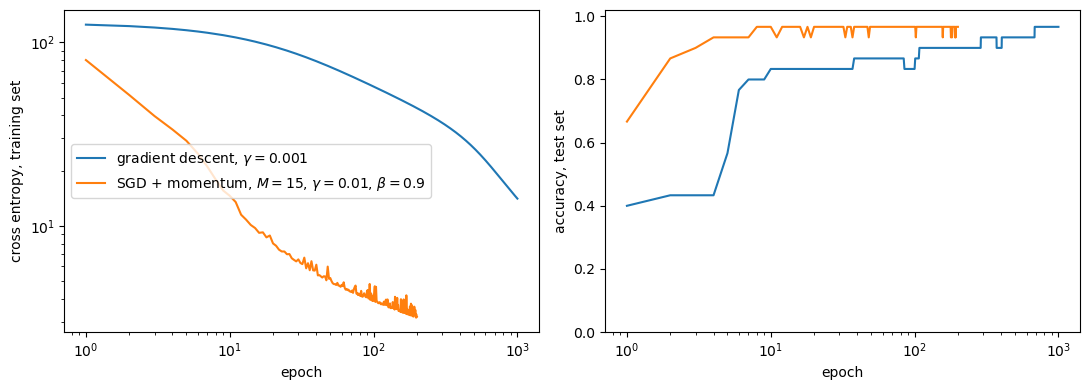

In [32]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(hist_gd[:, 0], hist_gd[:, 1], label="gradient descent, $\\gamma=0.001$")
ax1.plot(hist_sgd[:, 0], hist_sgd[:, 1], label="SGD + momentum, $M=15$, $\\gamma=0.01$, $\\beta=0.9$")
ax1.set_xlabel("epoch"); ax1.set_ylabel("cross entropy, training set"); ax1.set_xscale("log"); ax1.set_yscale("log"); ax1.legend()
ax2.plot(hist_gd[:, 0], hist_gd[:, 2]); ax2.plot(hist_sgd[:, 0], hist_sgd[:, 2])
ax2.set_xlabel("epoch"); ax2.set_ylabel("accuracy, test set"); ax2.set_xscale("log"); ax2.set_ylim(0, 1.02)
plt.tight_layout(); plt.show()

**Comparing with last week.** Full-batch gradient descent at
$\gamma = 0.001$ needs about a thousand epochs to bring the training cost
down to 14 and the test accuracy to 96.7% (29 of the 30 test flowers), as it
did last week. SGD with momentum is at the same cost and the same test
accuracy after **ten** epochs, and after 200 epochs its cost is 3.2 with a
training accuracy of 99.2%; the test accuracy stays at 96.7%, because the
same single flower is hard to classify. The number of *gradient
evaluations* per epoch is the same for both (eight minibatches of 15 cost
what one batch of 120 costs), so on this problem SGD with momentum is
roughly a hundred times cheaper for the same result. Two effects combine:
eight updates per epoch instead of one, and the momentum, which keeps the
step going in the direction the gradients agree on while the minibatch noise
averages out. The price is the noise visible in the cost curve and two more
hyperparameters ($M$ and $\beta$) to choose, and a large learning rate with
momentum overshoots: with $\gamma = 0.1$ the training cost goes lower still
(1.5 after 50 epochs) but the test accuracy drops to 90%.

The final test accuracies are the same because the iris data are easy: 150
nearly separable flowers, where almost any trained classifier makes the
same one or two mistakes. The difference between the two methods is how
long it takes to get there, not where they end up.


# Exercise 8 (optional) — object orientation

The class below stores the parameters and the functions that define the
network, and nothing else: no inputs, no outputs, no learning rate. The
gradient method stays outside, as a function (or a class with a `step`
method) that takes the list `layer_grads` and returns the parameter updates;
the network only applies them in `update_weights`. This separation is what
makes it easy to try gradient descent, momentum, RMSprop and Adam on the same
network in Project 2 — and to swap the network for another model under the
same optimizer.

`jax_compliant_predict(layers, inputs)` takes the layers as an explicit
argument so that `jax.grad` can differentiate with respect to them;
`jax_gradient` uses it to check `compute_gradient`. With the same seeds for
the initial weights and the shuffling, the class reproduces the numbers of
exercise 7b to every digit — the same algorithm, rearranged.


In [33]:
class NeuralNetwork:
    def __init__(
        self,
        network_input_size,
        layer_output_sizes,
        activation_funcs,
        activation_ders,
        cost_fun,
        cost_der,
        output_error=None,
        seed=2026,
    ):
        self.activation_funcs = activation_funcs
        self.activation_ders = activation_ders
        self.cost_fun = cost_fun
        self.cost_der = cost_der
        self.output_error = output_error     # e.g. a - y for softmax + cross entropy; None otherwise
        rng = np.random.default_rng(seed)
        sizes = [network_input_size] + list(layer_output_sizes)
        self.layers = [(rng.standard_normal((n_in, n_out)) / np.sqrt(n_in), np.zeros(n_out))
                       for n_in, n_out in zip(sizes[:-1], sizes[1:])]

    def predict(self, inputs):
        # Simple feed forward pass
        return self.jax_compliant_predict(self.layers, inputs)

    def cost(self, inputs, targets):
        return self.cost_fun(self.predict(inputs), targets)

    def _feed_forward_saver(self, inputs):
        layer_inputs, zs = [], []
        a = inputs
        for (W, b), f in zip(self.layers, self.activation_funcs):
            layer_inputs.append(a)
            z = a @ W + b
            a = f(z)
            zs.append(z)
        return layer_inputs, zs, a

    def compute_gradient(self, inputs, targets):
        layer_inputs, zs, predict = self._feed_forward_saver(inputs)
        layer_grads = [() for _ in self.layers]
        L = len(self.layers)
        for i in reversed(range(L)):
            layer_input, z = layer_inputs[i], zs[i]
            if i == L - 1 and self.output_error is not None:
                dC_dz = self.output_error(predict, targets)
            else:
                if i == L - 1:
                    dC_da = self.cost_der(predict, targets)
                else:
                    W_next, _ = self.layers[i + 1]
                    dC_da = dC_dz @ W_next.T
                dC_dz = dC_da * self.activation_ders[i](z)
            layer_grads[i] = (layer_input.T @ dC_dz, np.sum(dC_dz, axis=0))
        return layer_grads

    def update_weights(self, layer_updates):
        """Apply the updates (one (dW, db) per layer) computed by an optimizer outside the class."""
        self.layers = [(W - dW, b - db) for (W, b), (dW, db) in zip(self.layers, layer_updates)]

    # These last two methods are not needed in the project, but they can be nice to have!
    # The first one has a layers parameter so that you can use jax.grad on it.
    def jax_compliant_predict(self, layers, inputs):
        a = inputs
        for (W, b), f in zip(layers, self.activation_funcs):
            a = f(a @ W + b)
        return a

    def jax_gradient(self, inputs, targets):
        def cost_of_layers(layers):
            return self.cost_fun(self.jax_compliant_predict(layers, inputs), targets)
        return jax.grad(cost_of_layers)(self.layers)


class MomentumOptimizer:
    """Turns a list of gradients into a list of updates; knows nothing about the network."""

    def __init__(self, gamma, beta=0.9):
        self.gamma, self.beta, self.velocity = gamma, beta, None

    def step(self, layer_grads):
        if self.velocity is None:
            self.velocity = [(np.zeros_like(dW), np.zeros_like(db)) for dW, db in layer_grads]
        self.velocity = [(self.beta * vW + self.gamma * dW, self.beta * vb + self.gamma * db)
                         for (vW, vb), (dW, db) in zip(self.velocity, layer_grads)]
        return self.velocity

In [34]:
net = NeuralNetwork(4, [8, 3], [sigmoid, softmax], [sigmoid_der, None],
                    cross_entropy, None, output_error=output_error_softmax_ce)

# the hand-written gradient agrees with JAX
g_hand, g_jax = net.compute_gradient(X_tr, y_tr), net.jax_gradient(X_tr, y_tr)
print([(np.allclose(dW, dW_j), np.allclose(db, db_j)) for (dW, db), (dW_j, db_j) in zip(g_hand, g_jax)])

# the same training loop as in exercise 7b, now three lines per minibatch
optimizer = MomentumOptimizer(gamma=0.01, beta=0.9)
rng = np.random.default_rng(2026)
for epoch in range(1, 51):
    perm = rng.permutation(len(X_tr))
    for start in range(0, len(X_tr), 15):
        idx = perm[start:start + 15]
        grads = net.compute_gradient(X_tr[idx], y_tr[idx])
        net.update_weights(optimizer.step(grads))
    if epoch in (1, 5, 10, 20, 50):
        print("epoch %3d  cost %6.2f  train acc %.3f  test acc %.3f"
              % (epoch, float(net.cost(X_tr, y_tr)),
                 accuracy(net.predict(X_tr), y_tr), accuracy(net.predict(X_te), y_te)))

[(True, True), (True, True)]
epoch   1  cost  80.21  train acc 0.667  test acc 0.667
epoch   5  cost  29.09  train acc 0.900  test acc 0.933
epoch  10  cost  14.58  train acc 0.967  test acc 0.967
epoch  20  cost   8.01  train acc 0.975  test acc 0.967
epoch  50  cost   5.19  train acc 0.992  test acc 0.967


epoch  50  cost   5.19  train acc 0.992  test acc 0.967


# Discussion — the insights you should have gained

The exercises lead to a working `backpropagation` function, and that
function is the heart of Project 2. But the code is the smaller part of
what the week was about; the point was to understand what the algorithm
does well enough that you can change it. Here is what you should take with
you, with the places in the notebook where you saw it.

**1. A gradient has the shape of its parameter.** $\partial C/\partial W$
has the shape of $W$, $\partial C/\partial b$ the shape of $b$, in every
layer and in both conventions (exercises 2a and 6). If a shape does not
match, the formula is wrong, not the array. This is the first thing to check
when backpropagation fails, and the reason exercise 1 asked you to have the
shape table in front of you.

**2. The chain rule becomes an algorithm because the layers are a
composition.** Nothing in exercises 3–5 was more than the chain rule, applied
to a function of the form $C(f_L(W_L f_{L-1}(\cdots f_1(W_1 x + b_1)\cdots) + b_L))$.
Because the composition is a chain, the derivative factorises into a
product of local Jacobians, and because the chain ends at a *scalar*, we can
contract that product from the output end and never hold a Jacobian in
memory: exercise 3e showed that the three-index object $dz/dW$ exists but
collapses to the outer product $\delta x^T$ as soon as it is contracted with
the error, and 4b showed that the Jacobian $dz_2/da_1 = W_2$ only ever
appears as the product $W_2^T\delta_2$. That is what makes the algorithm
cheap — about the cost of two forward passes, independently of the number
of parameters — and it is why it goes backwards: the scalar is at the
output, so the contraction has to start there.

**3. The error $\delta^l = \partial C/\partial z^l$ is the quantity to
organise the computation around.** It is shared by the weight and the bias
gradient of a layer (3a), it *is* the bias gradient (3e), it gives the
weight gradient by an outer product with the layer input (3e), and it is
what one layer hands to the next (4b). The four equations of Section 8.8.4
say nothing else. The backward loop in exercise 5 carries a single variable
`dC_dz` from one iteration to the next; everything else is local to the
layer.

**4. The error flows backwards through the transposed weights.** The matrix
that sends activations forward sends errors backward, transposed:
$\delta^l = (W^{l+1})^T\delta^{l+1}\odot f'(z^l)$ (4b), or $\delta\,W^T$ with
samples in rows (6). Two consequences you have seen. Each sigmoid layer
multiplies the error by $\sigma'(z) \le 1/4$, and in exercise 4 the
first-layer error was already a quarter of the second-layer error after one
layer: the gradient *vanishes* with depth, which is why sigmoid networks
were hard to train deep and why the ReLU — derivative one wherever it is
active — took over. And a ReLU unit with $z < 0$ has $f'(z) = 0$: its error
and all its gradients are exactly zero, as the two zero rows in exercise 5
showed. For one input this is normal; a unit that is negative for all inputs
is dead and never recovers, which is one reason initial weights and inputs
need a sensible scale.

**5. The backward pass is evaluated at the forward pass.** $f'(z^l)$ needs
$z^l$ and $\partial C/\partial W^l$ needs $a^{l-1}$, so the forward pass must
save them (`feed_forward_saver`, exercise 5). `feed_forward` without the
saving is fine for predictions and for `jax.grad`, which does its own saving
internally. This is also the memory cost of training: every intermediate
activation of the batch is kept until the backward pass has used it, which is
what limits batch sizes and depths on a GPU.

**6. Batching is a bookkeeping change, not a new algorithm.** Samples in
rows, weights transposed, and three lines change: `dC_dz @ W.T`,
`layer_input.T @ dC_dz` and `dC_dz.sum(axis=0)` (exercise 6). The matrix
products sum the single-sample gradients over the batch — we checked that
the batched weight gradient is the mean of the ten single-sample gradients
when the cost is a mean. There is no loop over the samples anywhere, which
is what makes the method fast on hardware built for matrix products.

**7. Choose output activation and cost together.** The softmax Jacobian is a
full matrix per sample and the cross-entropy derivative has $1/a_k$ in it;
their product is $a - y$ (exercise 7a). The same cancellation holds for the
sigmoid with the binary cross entropy and for the identity output with the
squared error. One implements the shortcut, never the softmax derivative,
and the gradient check against `jax.grad` of the full composition confirms
it. The error that drives the training is then literally prediction minus
target: a confidently wrong sample has $|a - y|$ close to one and pulls
hardest; a correct and confident one hardly contributes.

**8. Constants matter until they don't.** `mse_der` carries the $2/n$ of the
mean (3b) and the cross entropy, being a sum, has no $1/n$ (7a). A missing
factor gives a gradient in the right direction with the wrong length, and
the learning rate absorbs it — until you compare numbers with `jax.grad`, or
with a classmate, or change the batch size and find that the same $\gamma$
no longer works. Knowing which normalisation your cost uses is what lets you
transfer a learning rate from one setting to another, as we did from last
week's 150-sample batch to this week's minibatches of 15.

**9. `jax.grad` and your code are the same algorithm.** They agreed to
$10^{-15}$ at every step, because reverse-mode automatic differentiation
*is* backpropagation: the same chain rule, contracted from the output in the
same order, at the same cost (Section 4.14). JAX records the operations of
the forward pass and applies their transposed Jacobians backwards, which is
exactly what your loop does — the difference is that JAX does it for any
program, not only for dense layers. Having written it once by hand you know
what the tool does, where its memory goes, and why it cannot differentiate
a function with a Python `if` on the data without tracing it.

**10. The gradient is only half of training.** With the gradient in hand,
full-batch gradient descent and SGD with momentum reach the same test
accuracy on the iris data, but SGD with momentum is there in ten epochs
where gradient descent needs a thousand (exercise 7b). Several updates per
pass over the data, each from a cheap noisy estimate of the gradient, beat
one exact update per pass; momentum turns the noisy steps into a steady
drift in the direction the minibatches agree on, and the noise itself helps
leave flat regions. The accuracy that counts is on data the network never
saw: the training accuracy of a 59-parameter network on 120 flowers tells
you little (Section [3.14](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter3.html)).

**11. Separate the network from the optimizer.** The class of exercise 8
stores parameters and functions, computes predictions and gradients, and
applies updates it is given. The optimizer turns gradients into updates and
knows nothing about layers. With this split, replacing momentum by Adam, or
the dense network by another model, is a one-line change — the structure
Project 2 asks for.

If you can explain the four equations of Section 8.8.4 from the shape table
of exercise 1, say what `feed_forward_saver` saves and why, write the three
lines that change for a batch, and derive $\delta^L = a - y$ for the softmax
with the cross entropy, you have what this week was meant to give you.
